<a href="https://colab.research.google.com/github/Abeer-24/NLP/blob/main/Sequence_Classification_using_RNN_LSTM_(Keras_TensorFlow).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

In [2]:
vocab_size = 10000

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training samples: 25000
Testing samples: 25000


In [3]:
max_length = 200

X_train = pad_sequences(
    X_train,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

X_test = pad_sequences(
    X_test,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (25000, 200)
Testing shape: (25000, 200)


In [4]:
model = Sequential([
    Embedding(vocab_size, 64),
    LSTM(64),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [5]:
history = model.fit(
    X_train,
    y_train,
    epochs=3,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 53s 161ms/step - accuracy: 0.5264 - loss: 0.6906 - val_accuracy: 0.6936 - val_loss: 0.6701
Epoch 2/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 78s 148ms/step - accuracy: 0.5832 - loss: 0.6729 - val_accuracy: 0.5064 - val_loss: 0.7046
Epoch 3/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 81s 144ms/step - accuracy: 0.5951 - loss: 0.6563 - val_accuracy: 0.7622 - val_loss: 0.5503


In [6]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy * 100, "%")

782/782 ━━━━━━━━━━━━━━━━━━━━ 22s 29ms/step - accuracy: 0.7517 - loss: 0.5650
Test Loss: 0.5650026798248291
Test Accuracy: 75.17200112342834 %


In [7]:
predictions = model.predict(X_test[:5])

for i, prediction in enumerate(predictions):
    sentiment = "Positive" if prediction[0] >= 0.5 else "Negative"

    print("Review", i + 1)
    print("Predicted Sentiment:", sentiment)
    print("Actual Sentiment:", "Positive" if y_test[i] == 1 else "Negative")
    print()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 209ms/step
Review 1
Predicted Sentiment: Negative
Actual Sentiment: Negative

Review 2
Predicted Sentiment: Positive
Actual Sentiment: Positive

Review 3
Predicted Sentiment: Positive
Actual Sentiment: Positive

Review 4
Predicted Sentiment: Negative
Actual Sentiment: Negative

Review 5
Predicted Sentiment: Negative
Actual Sentiment: Positive



In [8]:
word_index = imdb.get_word_index()

def predict_review(text):
    words = text.lower().split()

    sequence = [
        word_index.get(word, 2) + 3
        for word in words
    ]

    sequence = pad_sequences(
        [sequence],
        maxlen=max_length,
        padding='post',
        truncating='post'
    )

    prediction = model.predict(sequence, verbose=0)[0][0]

    sentiment = "Positive" if prediction >= 0.5 else "Negative"

    print("Review:", text)
    print("Prediction Score:", round(float(prediction), 4))
    print("Sentiment:", sentiment)

predict_review("This movie is amazing and I really enjoyed it")

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Review: This movie is amazing and I really enjoyed it
Prediction Score: 0.6029
Sentiment: Positive


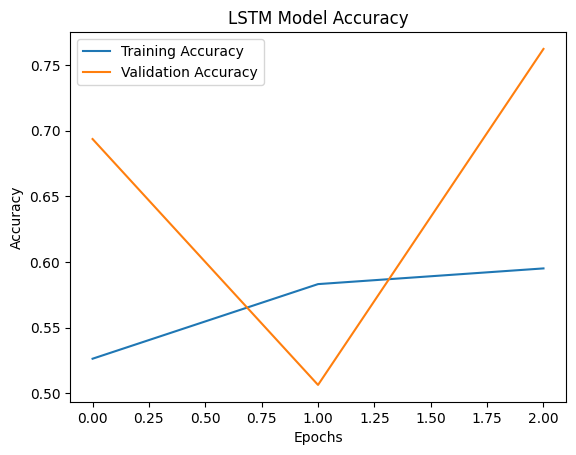

In [9]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("LSTM Model Accuracy")
plt.legend()
plt.show()